# Gravidade dos acidentes nas rodovias federais

Projeto final de Ciência de Dados (IC/UFAL).

## 0. Configuração

In [1]:
import re
import warnings
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
from matplotlib import patheffects
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier, early_stopping
from matplotlib.ticker import FuncFormatter, MultipleLocator, PercentFormatter
from scipy import sparse
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report,
                             precision_recall_curve, roc_auc_score)
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from statsmodels.stats.contingency_tables import Table2x2

# BRs que só aparecem depois do treino entram na regressão logística na categoria das infrequentes.
warnings.filterwarnings("ignore", message="Found unknown categories")

SEMENTE = 42
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#b4b2a9"
PCT = FuncFormatter(lambda v, _: f"{v * 100:g}%".replace(".", ","))  # porcentagem com vírgula decimal
DADOS = Path("dados/brutos")
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

# Contagens de vítimas: mortos e feridos definem a classificação, e nenhuma delas pode ser preditora.
CONTAGENS = ["mortos", "feridos_leves", "feridos_graves", "feridos", "ilesos", "ignorados"]

## 1. Carga

Arquivos da PRF agrupados por ocorrência, 2017 a 2025.

In [2]:
anos = [
    pd.read_csv(arquivo, sep=";", decimal=",", encoding="latin-1")
    for arquivo in sorted(DADOS.glob("ocorrencia_*.zip"))
]
assert all(list(ano.columns) == list(anos[0].columns) for ano in anos)

bruto = pd.concat(anos, ignore_index=True)
bruto["data_inversa"] = pd.to_datetime(bruto["data_inversa"])
bruto.shape

(632713, 30)

## 2. Visão geral

In [3]:
bruto["classificacao_acidente"].value_counts(dropna=False)

classificacao_acidente
Com Vítimas Feridas    462965
Sem Vítimas            126301
Com Vítimas Fatais      43437
NaN                        10
Name: count, dtype: int64

Acidentes por mês em cada classe.

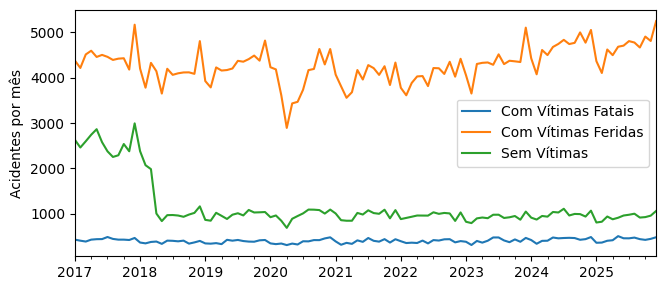

In [4]:
mensal = bruto.groupby(
    [bruto["data_inversa"].dt.to_period("M"), "classificacao_acidente"]
).size().unstack()

ax = mensal.plot(figsize=(7.5, 3.2))
ax.set(xlabel="", ylabel="Acidentes por mês")
ax.legend(title="")
plt.savefig(FIGURAS / "acidentes_por_classe.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Limpeza e preparação

### 3.1 Duplicatas e classificações nulas

Dez ocorrências repetem outra em tudo menos no `id` e são removidas. A classificação vazia é recuperada pelas contagens de mortos e feridos, a mesma regra que reproduz todas as classificações preenchidas.

In [5]:
df = bruto.drop_duplicates(subset=bruto.columns.drop("id")).copy()
funil = {"Ocorrências 2017–2025": len(bruto), "Sem duplicatas": len(df)}

derivada = np.select(
    [df["mortos"] > 0, df["feridos"] > 0],
    ["Com Vítimas Fatais", "Com Vítimas Feridas"],
    "Sem Vítimas",
)
assert (derivada == df["classificacao_acidente"]).sum() == df["classificacao_acidente"].notna().sum()
df["classificacao_acidente"] = derivada

### 3.2 Localização

Coordenadas fora do Brasil e BR = 0 viram ausentes. As ocorrências com BR = 0 são as mesmas com sentido "Não Informado".

In [6]:
fora = ~df["latitude"].between(-34, 5.5) | ~df["longitude"].between(-74, -34)
df.loc[fora, ["latitude", "longitude"]] = np.nan
df["br"] = df["br"].replace(0, np.nan).astype("Int64")
print(f"{fora.sum()} coordenadas fora do Brasil; {df['br'].isna().sum()} ocorrências sem BR")

54 coordenadas fora do Brasil; 1407 ocorrências sem BR


### 3.3 Categorias

Colisão lateral e colisão com objeto mudam de subdivisão em 2020–2021, então ficam só as categorias gerais. As causas mudam de nomenclatura quase inteira em 2021 e foram reunidas em grupos amplos por palavras-chave; a tabela mostra a participação de cada grupo por ano. "Ignorado" e "Não Informado" (clima e sentido) ficam como categorias próprias.

In [7]:
TIPOS = {
    "Colisão lateral mesmo sentido": "Colisão lateral",
    "Colisão lateral sentido oposto": "Colisão lateral",
    "Colisão com objeto estático": "Colisão com objeto",
    "Colisão com objeto em movimento": "Colisão com objeto",
    "Danos eventuais": "Outros",
    "Eventos atípicos": "Outros",
    "Sinistro pessoal de trânsito": "Outros",
}
df["tipo"] = df["tipo_acidente"].replace(TIPOS).fillna("Outros")

# Primeira regra que casar com o nome da causa (a ordem importa).
GRUPOS_CAUSA = [
    ("Pedestre", r"pedestre|travessia"),
    ("Álcool e drogas", r"álcool|psicoativ"),
    ("Velocidade", r"^velocidade"),
    ("Sono e saúde", r"dormindo|súbito|transtornos"),
    ("Desatenção e reação", r"atenção|reação|distância|celular|frear"),
    ("Manobra ou infração", r"ultrapassagem|contramão|conversão|retorno|mudança de faixa|preferência"
     r"|desobediência|acessar a via|acesso irregular|semáforo$|racha|estacionar|transitar"
     r"|entre as faixas|modificação|farol da moto"),
    ("Veículo", r"mecânic|pneu|freio|suspensão|carga|faróis|do veículo"),
    ("Animais", r"animais"),
    ("Clima", r"chuva|neblina|fumaça|fenômenos"),
    ("Via", r"pista|via|pavimento|acostamento|sinalização|curva|declive|obra|desvio|iluminação"
     r"|drenagem|semáforo|redutor|leito|faixas|visibilidade|desnível"),
]

def agrupar_causa(causa):
    for grupo, padrao in GRUPOS_CAUSA:
        if re.search(padrao, causa, re.IGNORECASE):
            return grupo
    return "Outros"

df["causa"] = df["causa_acidente"].map(agrupar_causa)
print(f"{df['tipo_acidente'].nunique()} tipos de acidente viram {df['tipo'].nunique()} "
      f"({df['tipo_acidente'].isna().sum()} sem tipo, em Outros); "
      f"{df['causa_acidente'].nunique()} causas viram {df['causa'].nunique()} grupos")
pd.crosstab(df["causa"], df["data_inversa"].dt.year, normalize="columns").round(3)

21 tipos de acidente viram 15 (41 sem tipo, em Outros); 91 causas viram 11 grupos


data_inversa,2017,2018,2019,2020,2021,2022,2023,2024,2025
causa,,,,,,,,,
Animais,0.029,0.023,0.023,0.022,0.019,0.020,0.020,0.020,0.018
Clima,0.005,0.004,0.003,0.004,0.023,0.021,0.018,0.018,0.016
Desatenção e reação,0.450,0.434,0.433,0.410,0.282,0.322,0.353,0.363,0.375
Manobra ou infração,0.081,0.123,0.137,0.157,0.272,0.274,0.285,0.290,0.290
Outros,0.000,0.005,0.006,0.005,0.000,0.000,0.001,0.003,0.003
Pedestre,0.027,0.037,0.040,0.037,0.037,0.037,0.034,0.029,0.028
Sono e saúde,0.053,0.048,0.047,0.042,0.046,0.042,0.039,0.037,0.038
Velocidade,0.116,0.099,0.089,0.093,0.104,0.077,0.063,0.059,0.056
Veículo,0.078,0.076,0.074,0.082,0.073,0.070,0.071,0.072,0.070


`tracado_via` pode ter vários valores na mesma ocorrência e vira uma coluna binária por valor.

In [8]:
tracados = df["tracado_via"].str.get_dummies(sep=";")
tracados.columns = "tracado_" + tracados.columns.str.lower().str.replace(" ", "_")
df = df.join(tracados)
tracados.mean().sort_values(ascending=False).round(3)

tracado_reta                     0.681
tracado_curva                    0.190
tracado_declive                  0.080
tracado_aclive                   0.062
tracado_interseção_de_vias       0.061
tracado_rotatória                0.024
tracado_retorno_regulamentado    0.019
tracado_em_obras                 0.015
tracado_viaduto                  0.013
tracado_ponte                    0.009
tracado_desvio_temporário        0.003
tracado_túnel                    0.000
dtype: float64

### 3.4 Novas variáveis

Hora, faixa horária, mês, ano, fim de semana e feriado nacional. Carnaval e Corpus Christi não são feriados nacionais e ficam de fora.

In [9]:
df["hora"] = pd.to_datetime(df["horario"], format="%H:%M:%S").dt.hour
df["faixa_horaria"] = pd.cut(df["hora"], [0, 6, 12, 18, 24], right=False, labels=["0–6h", "6–12h", "12–18h", "18–24h"])
df["ano"] = df["data_inversa"].dt.year
df["mes"] = df["data_inversa"].dt.month
df["dia_semana"] = df["data_inversa"].dt.dayofweek.map(dict(enumerate(["seg", "ter", "qua", "qui", "sex", "sáb", "dom"])))
feriados = holidays.Brazil(years=range(2017, 2026))
df["feriado"] = df["data_inversa"].dt.date.isin(feriados)
df["fim_de_semana"] = df["dia_semana"].isin(["sáb", "dom"])
df[["feriado", "fim_de_semana"]].mean().round(3)

feriado          0.026
fim_de_semana    0.329
dtype: float64

### 3.5 Recorte

Só acidentes com vítimas; o alvo é ser fatal ou não.

In [10]:
df = df[df["classificacao_acidente"] != "Sem Vítimas"].copy()
df["fatal"] = (df["classificacao_acidente"] == "Com Vítimas Fatais").astype(int)
funil["Com vítimas"] = len(df)
funil["Fatais"] = df["fatal"].sum()
taxa_ano = df.groupby("ano")["fatal"].mean()
print(f"Taxa de fatais por ano: de {taxa_ano.min():.1%} a {taxa_ano.max():.1%}")
pd.Series(funil, name="ocorrências").to_frame()

Taxa de fatais por ano: de 8.2% a 8.8%


,ocorrências
Ocorrências 2017–2025,632713
Sem duplicatas,632703
Com vítimas,506404
Fatais,43438


### 3.6 Mudanças de registro

Campos que mudam de registro ao longo dos anos ou que não batem entre si.

In [11]:
menor = df["pessoas"] < df[["mortos", "feridos", "ilesos", "ignorados"]].sum(axis=1)
print(f"Pessoas abaixo da soma das contagens: {menor.mean():.1%} "
      f"(fatais {menor[df['fatal'] == 1].mean():.1%}, demais {menor[df['fatal'] == 0].mean():.1%})")
# Fase do dia impossível para a hora: pleno dia de madrugada (0h–3h) ou plena noite à tarde (12h–16h).
# Às 5h e às 17h a fase varia com a região e a época do ano.
madrugada = (df["fase_dia"] == "Pleno dia") & (df["hora"] <= 3)
tarde = (df["fase_dia"] == "Plena Noite") & df["hora"].between(12, 16)
print(f"Fase do dia impossível para a hora: {madrugada.sum()} em pleno dia entre 0h e 3h, {tarde.sum()} em plena "
      f"noite entre 12h e 16h ({(madrugada | tarde).mean():.2%} dos acidentes)")
pd.DataFrame({
    "traçado com mais de um valor": df["tracado_via"].str.contains(";").groupby(df["ano"]).mean().round(3),
    "capotamentos": (df["tipo"] == "Capotamento").groupby(df["ano"]).sum(),
    "tombamentos": (df["tipo"] == "Tombamento").groupby(df["ano"]).sum(),
})

Pessoas abaixo da soma das contagens: 4.7% (fatais 9.5%, demais 4.2%)
Fase do dia impossível para a hora: 543 em pleno dia entre 0h e 3h, 329 em plena noite entre 12h e 16h (0.17% dos acidentes)


,traçado com mais de um valor,capotamentos,tombamentos
ano,,,
2017,0.059,3334,4117
2018,0.070,2020,4111
2019,0.078,1922,4382
2020,0.093,1523,4815
2021,0.101,1426,4912
2022,0.120,1284,5008
2023,0.245,1257,5279
2024,0.255,1228,5999
2025,0.261,1165,5928


## 4. Análise exploratória

In [12]:
df[["pessoas", "veiculos"]].describe().round(2)

,pessoas,veiculos
count,506404.00,506404.00
mean,2.64,1.98
std,2.11,1.08
min,1.00,1.00
25%,2.00,1.00
50%,2.00,2.00
75%,3.00,2.00
max,95.00,131.00


Associação entre as variáveis categóricas e com o alvo, pelo V de Cramér (0 = nenhuma, 1 = total).

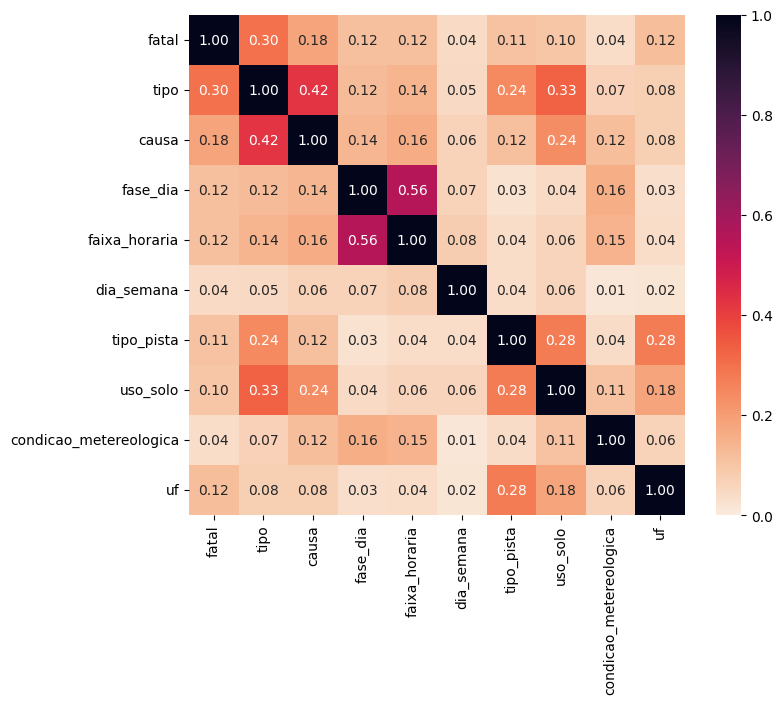

In [13]:
def cramer_v(a, b):
    return association(pd.crosstab(a, b).to_numpy(), method="cramer")

variaveis = ["fatal", "tipo", "causa", "fase_dia", "faixa_horaria", "dia_semana", "tipo_pista", "uso_solo",
             "condicao_metereologica", "uf"]
associacao = pd.DataFrame([[cramer_v(df[a], df[b]) for b in variaveis] for a in variaveis],
                          index=variaveis, columns=variaveis)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(associacao, annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=1, ax=ax)
plt.show()

Taxa de fatais entre os acidentes com vítimas. A linha tracejada é a taxa nacional; categorias com menos de 500 acidentes ficam de fora.

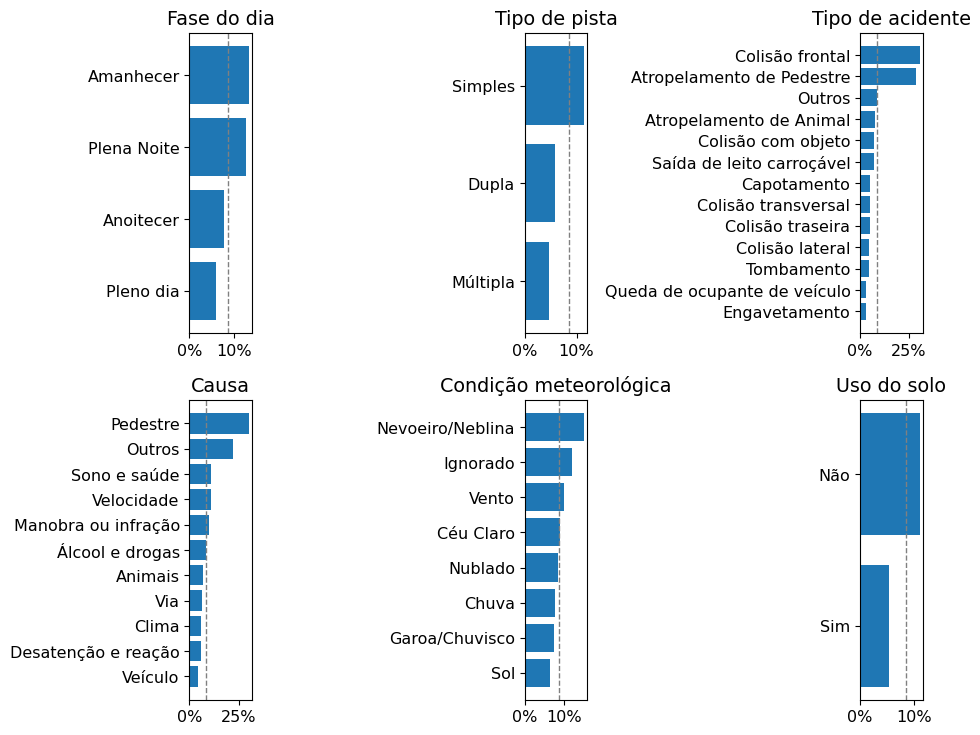

In [14]:
def taxa(dados, por):
    g = dados.groupby(por, observed=True)["fatal"].agg(acidentes="size", fatais="sum")
    g["taxa"] = g["fatais"] / g["acidentes"]
    return g.sort_values("taxa", ascending=False)

TAXA_BR = df["fatal"].mean()
ROTULOS = {"tipo": "Tipo de acidente", "causa": "Causa", "fase_dia": "Fase do dia", "faixa_horaria": "Faixa horária",
           "dia_semana": "Dia da semana", "condicao_metereologica": "Condição meteorológica",
           "tipo_pista": "Tipo de pista", "uso_solo": "Uso do solo", "uf": "UF", "br": "BR", "pessoas": "Pessoas",
           "veiculos": "Veículos", "mes": "Mês", "feriado": "Feriado"}
with plt.rc_context({"font.size": 11.5}):  # legível com a figura reduzida no artigo
    colunas = ["fase_dia", "tipo_pista", "tipo", "causa", "condicao_metereologica", "uso_solo"]
    fig, eixos = plt.subplots(2, 3, figsize=(9.5, 7.5))
    for col, ax in zip(colunas, eixos.flat):
        t = taxa(df, col).query("acidentes >= 500").sort_values("taxa")
        ax.barh(t.index.astype(str), t["taxa"])
        ax.axvline(TAXA_BR, color="gray", ls="--", lw=1)
        ax.set_title(ROTULOS[col])
        ax.xaxis.set_major_formatter(PCT)
    fig.tight_layout()
    fig.savefig(FIGURAS / "taxa_por_variavel.png", dpi=150, bbox_inches="tight")
    plt.show()

In [15]:
display(taxa(df, "tipo"), taxa(df, "causa"))
taxa(df, "condicao_metereologica")

,acidentes,fatais,taxa
tipo,,,
Colisão frontal,38404,11780,0.306739
Atropelamento de Pedestre,28174,8076,0.286647
Outros,1483,131,0.088334
Derramamento de carga,415,33,0.079518
Atropelamento de Animal,8443,667,0.079000
Colisão com objeto,32316,2350,0.072719
Saída de leito carroçável,73580,5228,0.071052
Capotamento,15159,787,0.051916
Colisão transversal,69580,3598,0.051710


,acidentes,fatais,taxa
causa,,,
Pedestre,20481,6186,0.302036
Outros,1204,268,0.222591
Sono e saúde,22857,2530,0.110688
Velocidade,42061,4622,0.109888
Manobra ou infração,117785,11958,0.101524
Álcool e drogas,26725,2194,0.082095
Animais,10449,717,0.068619
Via,33842,2172,0.064181
Clima,6158,352,0.057161


,acidentes,fatais,taxa
condicao_metereologica,,,
Nevoeiro/Neblina,3979,599,0.150540
Ignorado,7145,852,0.119244
Vento,940,94,0.100000
Céu Claro,305774,27320,0.089347
Nublado,83907,7058,0.084117
Granizo,12,1,0.083333
Chuva,52874,4097,0.077486
Garoa/Chuvisco,16801,1233,0.073388
Sol,34963,2184,0.062466


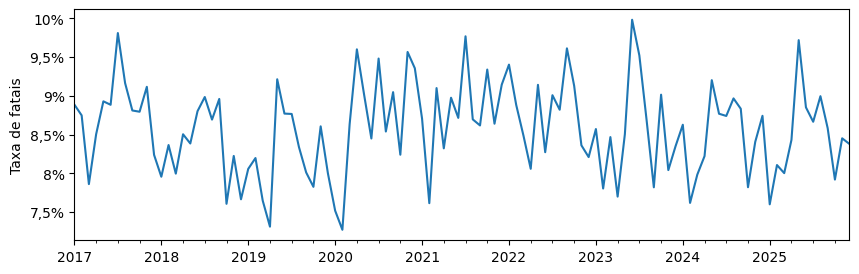

In [16]:
taxa_mensal = df.groupby(df["data_inversa"].dt.to_period("M"))["fatal"].mean()
ax = taxa_mensal.plot(figsize=(10, 3))
ax.set(xlabel="", ylabel="Taxa de fatais")
ax.yaxis.set_major_formatter(PCT)
plt.show()

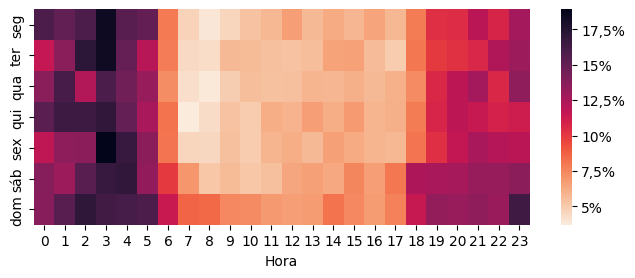

In [17]:
ordem = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
grade = df.pivot_table(index="dia_semana", columns="hora", values="fatal", aggfunc="mean").loc[ordem]
fig, ax = plt.subplots(figsize=(8, 2.8))
sns.heatmap(grade, cmap="rocket_r", cbar_kws={"format": PCT}, ax=ax)
ax.set(xlabel="Hora", ylabel="")
fig.savefig(FIGURAS / "taxa_dia_hora.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
pd.crosstab(df["fase_dia"], df["tipo_pista"], values=df["fatal"], aggfunc="mean").style.format("{:.1%}")

tipo_pista,Dupla,Múltipla,Simples
fase_dia,,,
Amanhecer,9.0%,8.3%,17.1%
Anoitecer,4.7%,3.3%,10.7%
Plena Noite,9.4%,8.1%,15.6%
Pleno dia,3.6%,2.8%,8.5%


In [19]:
taxa(df, "uf")

,acidentes,fatais,taxa
uf,,,
MA,8512,1817,0.213463
PA,7378,1350,0.182976
AM,779,134,0.172015
RR,1524,231,0.151575
TO,4450,664,0.149213
AL,4643,678,0.146026
BA,27733,3893,0.140374
PI,9668,1250,0.129293
PE,20368,2519,0.123674


No mapa, cada hexágono tem pelo menos 30 acidentes, e a escala de cor para em 30%.

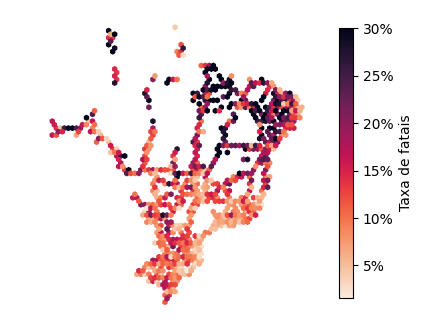

In [20]:
fig, ax = plt.subplots(figsize=(5, 5))
hb = ax.hexbin(df["longitude"], df["latitude"], C=df["fatal"], reduce_C_function=np.mean,
               gridsize=70, mincnt=30, vmax=0.3, cmap="rocket_r")
fig.colorbar(hb, format=PCT, label="Taxa de fatais", shrink=0.7)
ax.set_aspect("equal")
ax.set_axis_off()
fig.savefig(FIGURAS / "mapa_taxa.png", dpi=150, bbox_inches="tight")
plt.show()

### Alagoas e Brasil

In [21]:
al = df[df["uf"] == "AL"]
comparacao = pd.concat([
    pd.concat({"Brasil": taxa(df, col)["taxa"], "Alagoas": taxa(al, col)["taxa"],
               "acidentes em AL": taxa(al, col)["acidentes"]}, axis=1)
    for col in ["fase_dia", "tipo_pista"]
])
comparacao.loc["Total"] = [TAXA_BR, al["fatal"].mean(), len(al)]
comparacao.style.format({"Brasil": "{:.1%}", "Alagoas": "{:.1%}", "acidentes em AL": "{:.0f}"})

,Brasil,Alagoas,acidentes em AL
Amanhecer,13.3%,25.5%,216
Plena Noite,12.5%,19.7%,1829
Anoitecer,7.7%,14.0%,222
Pleno dia,5.9%,9.7%,2376
Simples,11.5%,15.5%,3157
Dupla,5.8%,12.6%,1463
Múltipla,4.7%,17.4%,23
Total,8.6%,14.6%,4643


In [22]:
taxa(al, "br").query("acidentes >= 100")

,acidentes,fatais,taxa
br,,,
423,319,73,0.228840
316,1406,198,0.140825
101,1767,238,0.134692
104,977,121,0.123849


## 5. Hipóteses

Teste qui-quadrado e razão de chances com intervalo de 95%, com correção de Bonferroni para os 5 testes.

In [23]:
ALFA = 0.05 / 5  # Bonferroni para as 5 hipóteses

def comparar(grupo_a, grupo_b, nomes):
    """Taxa de fatais em dois grupos, teste qui-quadrado e razão de chances com IC de 95%."""
    a = df.loc[grupo_a, "fatal"]
    b = df.loc[grupo_b, "fatal"]
    tabela = np.array([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]])
    _, p, _, _ = chi2_contingency(tabela)
    rc = Table2x2(tabela)
    ic = rc.oddsratio_confint()
    return pd.Series({
        "grupo A": nomes[0], "taxa A": a.mean(), "grupo B": nomes[1], "taxa B": b.mean(),
        "razão de chances": rc.oddsratio, "IC 95%": f"{ic[0]:.2f}–{ic[1]:.2f}",
        "p": p, "significativo": p < ALFA,
    })

resultados = {}

### H1. Plena noite × pleno dia

In [24]:
resultados["H1"] = comparar(df["fase_dia"] == "Plena Noite", df["fase_dia"] == "Pleno dia", ["noite", "dia"])
resultados["H1"]

grupo A                 noite
taxa A               0.125182
grupo B                   dia
taxa B               0.058848
razão de chances     2.288497
IC 95%              2.24–2.34
p                         0.0
significativo            True
dtype: object

### H2. Pista simples × dupla ou múltipla

In [25]:
resultados["H2"] = comparar(df["tipo_pista"] == "Simples", df["tipo_pista"] != "Simples", ["simples", "dupla/múltipla"])
resultados["H2"]

grupo A                    simples
taxa A                    0.115069
grupo B             dupla/múltipla
taxa B                    0.056029
razão de chances          2.190732
IC 95%                   2.15–2.24
p                              0.0
significativo                 True
dtype: object

### H3. Colisões frontais e atropelamentos de pedestres

In [26]:
graves = df["tipo"].isin(["Colisão frontal", "Atropelamento de Pedestre"])
print(f"{graves.mean():.1%} dos acidentes com vítimas e {graves[df['fatal'] == 1].mean():.1%} dos fatais")
resultados["H3"] = comparar(graves, ~graves, ["frontal/pedestre", "demais"])
resultados["H3"]

13.1% dos acidentes com vítimas e 45.7% dos fatais


grupo A             frontal/pedestre
taxa A                      0.298237
grupo B                       demais
taxa B                      0.053617
razão de chances             7.50132
IC 95%                     7.34–7.66
p                                0.0
significativo                   True
dtype: object

In [27]:
# Desde 2021, com a nomenclatura atual das causas.
frontais_2021 = df[(df["tipo"] == "Colisão frontal") & (df["ano"] >= 2021)]
print(frontais_2021["causa_acidente"].value_counts(normalize=True).head(3).round(3).to_string())
frontais = taxa(frontais_2021, "causa")
frontais["% das frontais"] = frontais["acidentes"] / frontais["acidentes"].sum()
frontais.sort_values("acidentes", ascending=False).head(5)

causa_acidente
Transitar na contramão              0.329
Ultrapassagem Indevida              0.129
Ingestão de álcool pelo condutor    0.072


,acidentes,fatais,taxa,% das frontais
causa,,,,
Manobra ou infração,13563,4627,0.341149,0.629257
Desatenção e reação,2533,662,0.261350,0.117519
Álcool e drogas,1592,308,0.193467,0.073861
Sono e saúde,1123,347,0.308994,0.052102
Velocidade,1012,341,0.336957,0.046952


### H4. Fins de semana e feriados × dias úteis

In [28]:
folga = df["fim_de_semana"] | df["feriado"]
resultados["H4"] = comparar(folga, ~folga, ["fim de semana/feriado", "dia útil"])
resultados["H4"]

grupo A             fim de semana/feriado
taxa A                           0.102417
grupo B                          dia útil
taxa B                           0.077151
razão de chances                  1.36486
IC 95%                          1.34–1.39
p                                     0.0
significativo                        True
dtype: object

### H5. Chuva × céu claro ou sol

In [29]:
resultados["H5"] = comparar(
    df["condicao_metereologica"] == "Chuva",
    df["condicao_metereologica"].isin(["Céu Claro", "Sol"]),
    ["chuva", "céu claro/sol"],
)
resultados["H5"]

grupo A                     chuva
taxa A                   0.077486
grupo B             céu claro/sol
taxa B                   0.086589
razão de chances         0.886045
IC 95%                  0.86–0.92
p                             0.0
significativo                True
dtype: object

### Resumo

In [30]:
pd.DataFrame(resultados).T

,grupo A,taxa A,grupo B,taxa B,razão de chances,IC 95%,p,significativo
H1,noite,0.125182,dia,0.058848,2.288497,2.24–2.34,0.0,True
H2,simples,0.115069,dupla/múltipla,0.056029,2.190732,2.15–2.24,0.0,True
H3,frontal/pedestre,0.298237,demais,0.053617,7.50132,7.34–7.66,0.0,True
H4,fim de semana/feriado,0.102417,dia útil,0.077151,1.36486,1.34–1.39,0.0,True
H5,chuva,0.077486,céu claro/sol,0.086589,0.886045,0.86–0.92,0.0,True


## 6. Modelagem

### 6.1 Variáveis e divisão temporal

As contagens de vítimas ficam de fora; `pessoas` e `veiculos` entram. O sentido da via também fica de fora, porque o valor "Não Informado" coincide exatamente com a BR ausente e tornaria singular a matriz da regressão logística. Treino com 2017–2022, validação com 2023 (número de árvores e limiar) e teste com 2024–2025, usado uma vez no fim.

In [31]:
CATEGORICAS = ["uf", "br", "fase_dia", "faixa_horaria", "dia_semana", "condicao_metereologica",
               "tipo_pista", "uso_solo", "tipo", "causa"]
BINARIAS = ["feriado", *tracados.columns]
NUMERICAS = ["pessoas", "veiculos", "mes"]
X = df[CATEGORICAS + BINARIAS + NUMERICAS].copy()
X[CATEGORICAS] = X[CATEGORICAS].astype(str).astype("category")
X[BINARIAS] = X[BINARIAS].astype(int)
assert X.columns.intersection(CONTAGENS).empty
y = df["fatal"]

treino = df["ano"] <= 2022
validacao = df["ano"] == 2023
teste = df["ano"] >= 2024
pd.DataFrame({
    "acidentes": [treino.sum(), validacao.sum(), teste.sum()],
    "taxa de fatais": [y[treino].mean(), y[validacao].mean(), y[teste].mean()],
}, index=["treino (2017–2022)", "validação (2023)", "teste (2024–2025)"])

,acidentes,taxa de fatais
treino (2017–2022),326791,0.086125
validação (2023),56803,0.085524
teste (2024–2025),122810,0.084969


### 6.2 Modelos

Referência que prevê sempre a taxa do treino, regressão logística e LightGBM, sem pesos de classe; a métrica principal é a PR-AUC, e o limiar de decisão é escolhido na validação. Na regressão logística, cada variável categórica tem como referência a categoria mais frequente no treino, o mês entra como categoria, com janeiro como referência, e as contagens entram em escala logarítmica. A faixa horária fica fora da regressão logística: ela se sobrepõe à fase do dia, e com as duas o efeito da noite se dividiria entre os coeficientes.

In [32]:
CATEGORICAS_LOG = [c for c in CATEGORICAS if c != "faixa_horaria"]
REFERENCIAS = [X.loc[treino, col].value_counts().index[0] for col in CATEGORICAS_LOG]
logistica = make_pipeline(
    ColumnTransformer([
        ("cat", OneHotEncoder(drop=REFERENCIAS, handle_unknown="infrequent_if_exist", min_frequency=100),
         CATEGORICAS_LOG),
        ("fora", "drop", ["faixa_horaria"]),
        ("contagens", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()),
         ["pessoas", "veiculos"]),
        ("mes", OneHotEncoder(drop="first"), ["mes"]),
    ], remainder="passthrough"),
    LogisticRegression(penalty=None, solver="newton-cholesky"),
)
logistica.fit(X[treino], y[treino])

boosting = LGBMClassifier(
    n_estimators=2000, learning_rate=0.05, num_leaves=63, min_child_samples=100,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    metric="average_precision", random_state=SEMENTE, verbose=-1,
)
boosting.fit(X[treino], y[treino], eval_set=[(X[validacao], y[validacao])],
             callbacks=[early_stopping(100, verbose=False)])
print("árvores:", boosting.best_iteration_)

modelos = {"referência": DummyClassifier(strategy="prior").fit(X[treino], y[treino]),
           "regressão logística": logistica, "LightGBM": boosting}

árvores: 134


In [33]:
def avaliar(conjunto):
    linhas = {}
    for nome, modelo in modelos.items():
        p = modelo.predict_proba(X[conjunto])[:, 1]
        linhas[nome] = {"PR-AUC": average_precision_score(y[conjunto], p),
                        "ROC-AUC": roc_auc_score(y[conjunto], p)}
    return pd.DataFrame(linhas).T

avaliar(validacao)

,PR-AUC,ROC-AUC
referência,0.085524,0.50000
regressão logística,0.338480,0.81225
LightGBM,0.364614,0.82987


### 6.3 Avaliação no teste

In [34]:
# Limiar escolhido na validação: o que maximiza o F1 do LightGBM.
p_val = boosting.predict_proba(X[validacao])[:, 1]
prec, rev, limiares = precision_recall_curve(y[validacao], p_val)
f1 = 2 * prec * rev / (prec + rev + 1e-12)
LIMIAR = limiares[f1[:-1].argmax()]
print(f"limiar {LIMIAR:.2f}")
avaliar(teste)

limiar 0.22


,PR-AUC,ROC-AUC
referência,0.084969,0.500000
regressão logística,0.333380,0.814419
LightGBM,0.363236,0.833878


In [35]:
# PR-AUC em cada ano do teste e intervalo bootstrap (200 reamostragens) da vantagem do LightGBM sobre a regressão.
por_ano = {ano: {nome: average_precision_score(y[df["ano"] == ano], m.predict_proba(X[df["ano"] == ano])[:, 1])
                 for nome, m in modelos.items()} for ano in (2024, 2025)}
display(pd.DataFrame(por_ano).round(3))

p_lgbm = boosting.predict_proba(X[teste])[:, 1]
p_log = logistica.predict_proba(X[teste])[:, 1]
y_teste = y[teste].to_numpy()
rng = np.random.default_rng(SEMENTE)
diferencas = []
for _ in range(200):
    i = rng.integers(0, len(y_teste), len(y_teste))
    diferencas.append(average_precision_score(y_teste[i], p_lgbm[i]) - average_precision_score(y_teste[i], p_log[i]))
print("Vantagem do LightGBM em PR-AUC: {:.3f} (IC 95%: {:.3f} a {:.3f})".format(
    average_precision_score(y_teste, p_lgbm) - average_precision_score(y_teste, p_log), *np.percentile(diferencas, [2.5, 97.5])))

,2024,2025
referência,0.085,0.085
regressão logística,0.341,0.326
LightGBM,0.370,0.357


Vantagem do LightGBM em PR-AUC: 0.030 (IC 95%: 0.026 a 0.034)


              precision    recall  f1-score   support

   não fatal      0.950     0.927     0.938    112375
       fatal      0.374     0.470     0.417     10435

    accuracy                          0.888    122810
   macro avg      0.662     0.698     0.677    122810
weighted avg      0.901     0.888     0.894    122810



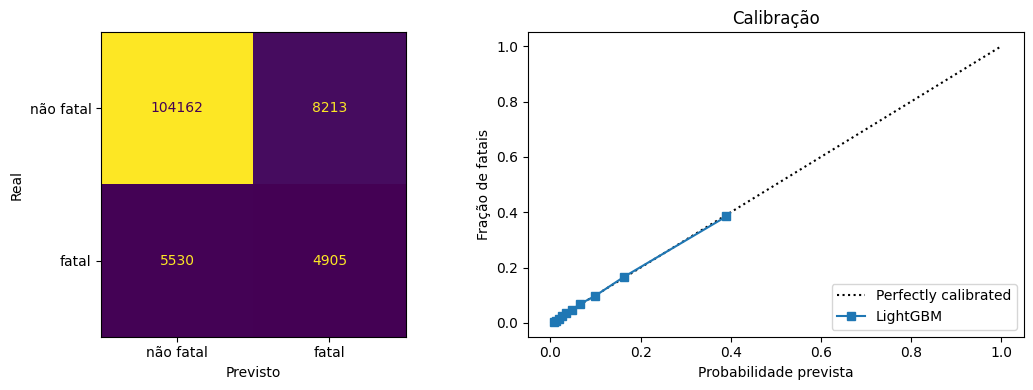

In [36]:
p_teste = boosting.predict_proba(X[teste])[:, 1]
print(classification_report(y[teste], p_teste >= LIMIAR, target_names=["não fatal", "fatal"], digits=3))
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y[teste], p_teste >= LIMIAR, display_labels=["não fatal", "fatal"],
                                        values_format="d", colorbar=False, ax=eixos[0])
eixos[0].set(xlabel="Previsto", ylabel="Real")
CalibrationDisplay.from_predictions(y[teste], p_teste, n_bins=10, strategy="quantile", name="LightGBM", ax=eixos[1])
eixos[1].set(xlabel="Probabilidade prevista", ylabel="Fração de fatais", title="Calibração")
fig.tight_layout()
plt.show()

In [37]:
# Verificação: o número de pessoas é menor que a soma das contagens de vítimas em cerca de 5% das ocorrências,
# mais nos fatais. Quanto o desempenho muda sem essa variável?
sem_pessoas = [c for c in X.columns if c != "pessoas"]
boosting_sem_pessoas = clone(boosting).fit(X.loc[treino, sem_pessoas], y[treino],
                                           eval_set=[(X.loc[validacao, sem_pessoas], y[validacao])],
                                           callbacks=[early_stopping(100, verbose=False)])
p = boosting_sem_pessoas.predict_proba(X.loc[validacao, sem_pessoas])[:, 1]
print(f"LightGBM sem pessoas: PR-AUC {average_precision_score(y[validacao], p):.3f} na validação "
      f"(com pessoas: {average_precision_score(y[validacao], p_val):.3f})")

LightGBM sem pessoas: PR-AUC 0.361 na validação (com pessoas: 0.365)


## 7. Interpretação

Razões de chances da regressão logística, cada uma em relação à categoria de referência da sua variável.

In [38]:
nomes = logistica[0].get_feature_names_out()
chances = pd.Series(np.exp(logistica[-1].coef_[0]), index=nomes).rename("razão de chances")
chances.index = chances.index.str.replace(r"^[a-z]+__", "", regex=True)
print("Referências:", dict(zip(CATEGORICAS_LOG, REFERENCIAS)))

# Intervalos de 95% de Wald, pela matriz de informação do ajuste (o scikit-learn não os calcula).
Xt = sparse.hstack([sparse.csr_matrix(np.ones((treino.sum(), 1))), logistica[0].transform(X[treino])]).tocsr()
p_treino = logistica.predict_proba(X[treino])[:, 1]
informacao = (Xt.T @ Xt.multiply((p_treino * (1 - p_treino))[:, None])).toarray()
erro = pd.Series(np.sqrt(np.diag(np.linalg.inv(informacao)))[1:], index=chances.index)
coef = np.log(chances)
tabela_rc = pd.DataFrame({"razão de chances": chances, "IC inferior": np.exp(coef - 1.96 * erro),
                          "IC superior": np.exp(coef + 1.96 * erro)})
tabela_rc[tabela_rc.index.str.match(r"(fase_dia|tipo_pista|uso_solo|tipo|causa)_|pessoas|veiculos")].round(2)

Referências: {'uf': 'MG', 'br': '101', 'fase_dia': 'Pleno dia', 'dia_semana': 'sáb', 'condicao_metereologica': 'Céu Claro', 'tipo_pista': 'Simples', 'uso_solo': 'Não', 'tipo': 'Colisão traseira', 'causa': 'Desatenção e reação'}


,razão de chances,IC inferior,IC superior
fase_dia_Amanhecer,2.04,1.93,2.16
fase_dia_Anoitecer,1.21,1.14,1.29
fase_dia_Plena Noite,1.97,1.91,2.03
tipo_pista_Dupla,0.80,0.77,0.83
tipo_pista_Múltipla,0.77,0.72,0.82
uso_solo_Sim,0.54,0.52,0.56
tipo_Atropelamento de Animal,3.19,2.59,3.93
tipo_Atropelamento de Pedestre,6.17,5.73,6.63
tipo_Capotamento,1.52,1.38,1.67
tipo_Colisão com objeto,2.47,2.30,2.65


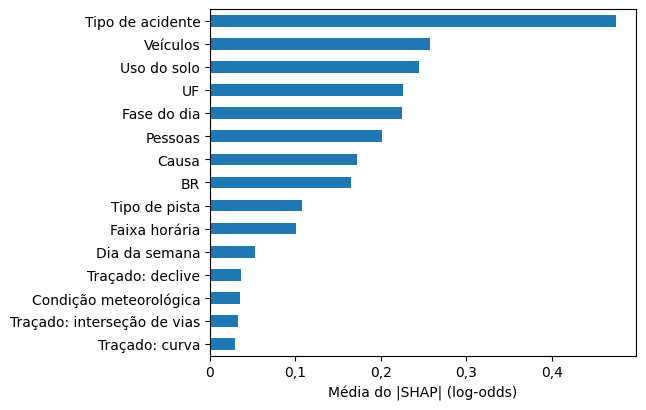

In [39]:
# Valores SHAP calculados pelo próprio LightGBM (TreeSHAP), numa amostra do teste.
amostra = X[teste].sample(20_000, random_state=SEMENTE)
contrib = pd.DataFrame(boosting.predict(amostra, pred_contrib=True)[:, :-1], columns=X.columns, index=amostra.index)
importancia = contrib.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
importancia.tail(15).rename(lambda c: ROTULOS.get(c, c.replace("tracado_", "Traçado: ").replace("_", " "))).plot.barh(ax=ax)
ax.set(xlabel="Média do |SHAP| (log-odds)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
fig.savefig(FIGURAS / "shap.png", dpi=150, bbox_inches="tight")
plt.show()

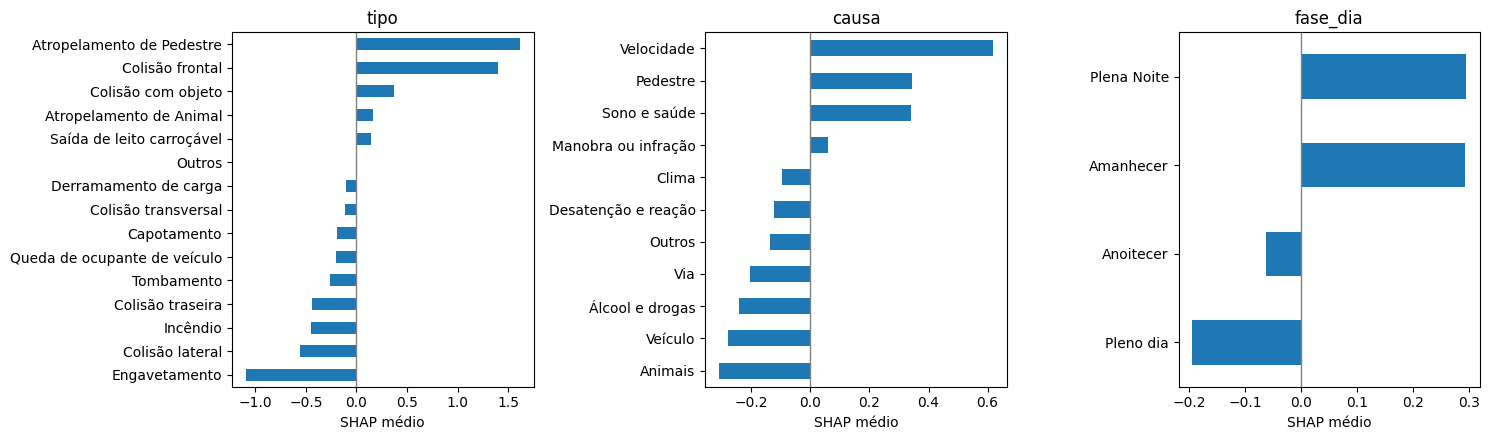

In [40]:
# Efeito médio de cada categoria nas variáveis mais importantes.
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
for col, ax in zip(["tipo", "causa", "fase_dia"], eixos):
    contrib.groupby(amostra[col], observed=True)[col].mean().sort_values().plot.barh(ax=ax)
    ax.axvline(0, color="gray", lw=1)
    ax.set(title=col, xlabel="SHAP médio", ylabel="")
fig.tight_layout()
plt.show()

## 8. Onde e quando priorizar

Trechos de 10 km de cada BR em cada UF, ordenados pelo número de acidentes fatais.

In [41]:
df["trecho"] = (df["uf"] + " BR-" + df["br"].astype(str).str.zfill(3) + " km "
                + (df["km"] // 10 * 10).astype("Int64").astype(str) + "–"
                + (df["km"] // 10 * 10 + 10).astype("Int64").astype(str))
com_trecho = df[df["br"].notna()]

def trechos(dados):
    return taxa(dados, "trecho").sort_index().sort_values("fatais", ascending=False, kind="stable")

ranking = trechos(com_trecho)
corte = ranking["fatais"].iloc[99]  # corte pelo número de fatais do 100º, para não depender de empates
no_corte = ranking["fatais"] >= corte
print(f"{len(ranking)} trechos; os {no_corte.sum()} com pelo menos {corte} fatais têm "
      f"{ranking.loc[no_corte, 'fatais'].sum() / ranking['fatais'].sum():.1%} dos acidentes fatais")
ranking.head(15)

6757 trechos; os 107 com pelo menos 34 fatais têm 11.9% dos acidentes fatais


,acidentes,fatais,taxa
trecho,,,
SP BR-116 km 220–230,2955,109,0.036887
SP BR-116 km 210–220,2553,108,0.042303
SP BR-381 km 80–90,1068,104,0.097378
RJ BR-116 km 170–180,1672,86,0.051435
SC BR-101 km 200–210,4501,85,0.018885
RJ BR-116 km 180–190,1331,83,0.062359
PE BR-101 km 70–80,1356,80,0.058997
MG BR-381 km 480–490,2090,78,0.037321
PE BR-101 km 50–60,925,76,0.082162


In [42]:
# Os trechos críticos se mantêm? Ranking de 2017–2022 comparado com 2024–2025.
passado = trechos(com_trecho[com_trecho["ano"] <= 2022])
recente = com_trecho[com_trecho["ano"] >= 2024]
corte_passado = passado["fatais"].iloc[99]
no_top = recente["trecho"].isin(passado.index[passado["fatais"] >= corte_passado])
print(f"Os {(passado['fatais'] >= corte_passado).sum()} trechos com pelo menos {corte_passado} fatais em 2017–2022 "
      f"tiveram {no_top.mean():.1%} dos acidentes com vítimas e "
      f"{recente.loc[no_top, 'fatal'].sum() / recente['fatal'].sum():.1%} dos fatais de 2024–2025.")

Os 107 trechos com pelo menos 23 fatais em 2017–2022 tiveram 19.6% dos acidentes com vítimas e 11.1% dos fatais de 2024–2025.


### Fatais acima do esperado

O LightGBM é reajustado só com o perfil de cada acidente (tipo, causa, fase do dia, faixa horária, dia da semana, clima, feriado, mês e números de pessoas e de veículos), sem o local nem as características da via, com os mesmos hiperparâmetros e número de árvores. A validação cruzada em cinco partes consecutivas, que equivalem a blocos de cerca de dois anos, dá a cada acidente a probabilidade estimada por um modelo que não o viu. Somadas por trecho, essas probabilidades são os fatais esperados, e o excesso é a diferença entre observados e esperados.

In [43]:
PERFIL = ["tipo", "causa", "fase_dia", "faixa_horaria", "dia_semana", "condicao_metereologica",
          "feriado", "mes", "pessoas", "veiculos"]
modelo_perfil = clone(boosting).set_params(n_estimators=boosting.best_iteration_)
df["esperado"] = cross_val_predict(modelo_perfil, X[PERFIL], y, cv=5, method="predict_proba")[:, 1]
print(f"Fatais observados: {df['fatal'].sum()}; esperados pelo perfil: {df['esperado'].sum():.0f}")
print("Observados/esperados por ano:", (df.groupby("ano")["fatal"].sum() / df.groupby("ano")["esperado"].sum()).round(2).to_dict())

def acima_do_esperado(dados, esperado=df["esperado"]):
    t = dados.assign(esperado=esperado).groupby("trecho").agg(
        acidentes=("fatal", "size"), fatais=("fatal", "sum"), esperados=("esperado", "sum"))
    t["excesso"] = t["fatais"] - t["esperados"]
    t["observados/esperados"] = t["fatais"] / t["esperados"]
    return t.sort_values("excesso", ascending=False)

excesso = acima_do_esperado(com_trecho)
print(f"Mediana de acidentes nos 50 trechos com maior excesso: {excesso.head(50)['acidentes'].median():.0f}; "
      f"nos 50 com mais fatais: {ranking.head(50)['acidentes'].median():.0f}")
excesso.head(15).round(2)

Fatais observados: 43438; esperados pelo perfil: 43458
Observados/esperados por ano: {2017: 1.05, 2018: 0.98, 2019: 0.97, 2020: 1.01, 2021: 1.0, 2022: 0.98, 2023: 0.98, 2024: 0.99, 2025: 1.03}


Mediana de acidentes nos 50 trechos com maior excesso: 97; nos 50 com mais fatais: 1068


,acidentes,fatais,esperados,excesso,observados/esperados
trecho,,,,,
MA BR-316 km 610–620,157,52,21.90,30.10,2.37
PE BR-232 km 50–60,206,44,18.55,25.45,2.37
PA BR-316 km 20–30,251,44,21.56,22.44,2.04
PE BR-232 km 210–220,82,35,12.62,22.38,2.77
AL BR-101 km 170–180,108,33,15.89,17.11,2.08
MT BR-364 km 340–350,281,39,22.42,16.58,1.74
PA BR-010 km 310–320,52,25,8.44,16.56,2.96
CE BR-222 km 120–130,132,34,17.45,16.55,1.95
PE BR-408 km 60–70,98,27,11.08,15.92,2.44


In [44]:
# O excesso se mantém? Os 50 trechos com maior excesso em 2017–2022, vistos em 2024–2025.
def razao(t):
    return t["fatais"].sum() / t["esperados"].sum()

antes = com_trecho[com_trecho["ano"] <= 2022]
depois = com_trecho[com_trecho["ano"] >= 2024]
top = acima_do_esperado(antes).head(50)
seguem = acima_do_esperado(depois).loc[lambda t: t.index.isin(top.index)]
print(f"Ranking nacional: {razao(top):.2f} vezes o esperado em 2017–2022 e {razao(seguem):.2f} em 2024–2025 "
      f"({seguem['fatais'].sum()} fatais para {seguem['esperados'].sum():.0f} esperados).")

# O mesmo com o esperado ajustado pela razão observados/esperados de cada UF em 2017–2022.
fator_uf = antes.groupby("uf")["fatal"].sum() / df.loc[antes.index, "esperado"].groupby(antes["uf"]).sum()
print("Razão observados/esperados por UF em 2017–2022 (extremos):",
      fator_uf.sort_values().round(2).iloc[[0, 1, 2, -3, -2, -1]].to_dict())
esperado_uf = df["esperado"] * df["uf"].map(fator_uf)
top_uf = acima_do_esperado(antes, esperado_uf).head(50)
seguem_uf = acima_do_esperado(depois, esperado_uf).loc[lambda t: t.index.isin(top_uf.index)]
print(f"Com ajuste por UF: {razao(top_uf):.2f} vezes o esperado em 2017–2022 e {razao(seguem_uf):.2f} em 2024–2025 "
      f"({seguem_uf['fatais'].sum()} fatais para {seguem_uf['esperados'].sum():.0f} esperados).")

Ranking nacional: 2.21 vezes o esperado em 2017–2022 e 1.63 em 2024–2025 (265 fatais para 163 esperados).
Razão observados/esperados por UF em 2017–2022 (extremos): {'SC': 0.65, 'ES': 0.7, 'DF': 0.75, 'PI': 1.52, 'PA': 1.64, 'MA': 1.88}


Com ajuste por UF: 1.79 vezes o esperado em 2017–2022 e 1.29 em 2024–2025 (303 fatais para 235 esperados).


In [45]:
# Verificações do ranking: perfil ajustado só com 2017–2022 e perfil sem o número de pessoas.
def verificar(esperado, nome):
    escolhidos = acima_do_esperado(antes, esperado).head(50)
    depois_t = acima_do_esperado(depois, esperado).loc[lambda t: t.index.isin(escolhidos.index)]
    print(f"{nome}: {razao(escolhidos):.2f} vezes o esperado em 2017–2022 e {razao(depois_t):.2f} em 2024–2025 "
          f"({depois_t['fatais'].sum()} fatais para {depois_t['esperados'].sum():.0f} esperados); "
          f"{escolhidos.index.isin(top.index).sum()} dos 50 trechos em comum com o ranking original")

ate_2022 = df["ano"] <= 2022
so_periodo = pd.Series(np.nan, index=df.index)
so_periodo[ate_2022] = cross_val_predict(modelo_perfil, X.loc[ate_2022, PERFIL], y[ate_2022], cv=5,
                                         method="predict_proba")[:, 1]
so_periodo[~ate_2022] = (clone(modelo_perfil).fit(X.loc[ate_2022, PERFIL], y[ate_2022])
                         .predict_proba(X.loc[~ate_2022, PERFIL])[:, 1])
verificar(so_periodo, "Perfil ajustado só com 2017–2022")

perfil_sem_pessoas = [c for c in PERFIL if c != "pessoas"]
verificar(pd.Series(cross_val_predict(modelo_perfil, X[perfil_sem_pessoas], y, cv=5, method="predict_proba")[:, 1],
                    index=df.index), "Perfil sem o número de pessoas")

Perfil ajustado só com 2017–2022: 2.19 vezes o esperado em 2017–2022 e 1.62 em 2024–2025 (264 fatais para 163 esperados); 48 dos 50 trechos em comum com o ranking original


Perfil sem o número de pessoas: 2.24 vezes o esperado em 2017–2022 e 1.64 em 2024–2025 (263 fatais para 160 esperados); 48 dos 50 trechos em comum com o ranking original


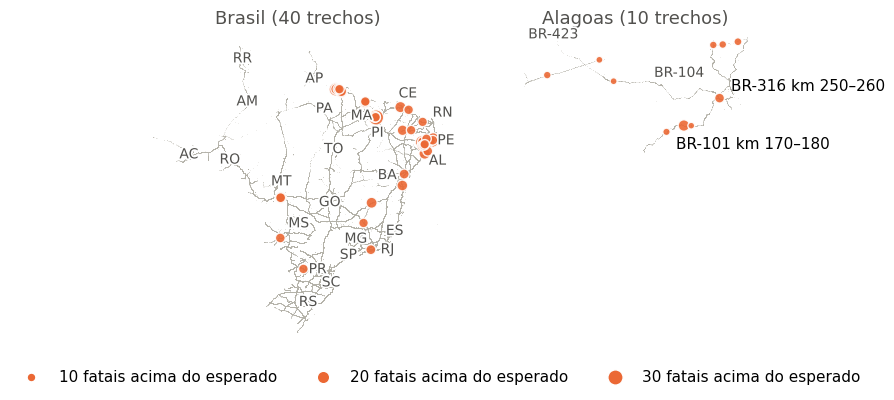

In [46]:
def mapa_trechos(largura, fonte, n_brasil=40, n_alagoas=10):
    """Trechos com maior excesso no Brasil e em Alagoas, com siglas das UFs e nomes das BRs de Alagoas."""
    centro = com_trecho.groupby("trecho")[["longitude", "latitude"]].mean()
    pontos = excesso.join(centro)
    pontos_al = pontos[pontos.index.str.startswith("AL ")]
    escala = 9 * (largura / 12) ** 2  # área do círculo por acidente fatal em excesso

    fig, (ax_br, ax_al) = plt.subplots(1, 2, figsize=(largura, largura * 0.52), gridspec_kw={"width_ratios": [1.3, 1]})
    for ax, dados, top in [(ax_br, df, pontos.head(n_brasil)), (ax_al, df[df["uf"] == "AL"], pontos_al.head(n_alagoas))]:
        ax.scatter(dados["longitude"], dados["latitude"], s=0.2, color=CINZA, alpha=0.35, linewidths=0, rasterized=True)
        ax.scatter(top["longitude"], top["latitude"], s=top["excesso"] * escala, color=LARANJA, edgecolor="white",
                   linewidth=1, alpha=0.9, zorder=3)
        ax.set_aspect("equal")
        ax.set_anchor("N")
        ax.set_axis_off()

    def posicionar(rotulos, centros, raio, extras=()):
        """Põe cada rótulo na posição original ou, se estiver a menos de `raio` (em graus) de um círculo ou de
        outro rótulo, na melhor de oito direções ao redor; sem posição livre, vai para leste (o mar, no litoral)."""
        posicoes, ocupados = {}, [tuple(c) for c in centros] + list(extras)
        def folga(px, py):
            return min(np.hypot(ox - px, oy - py) for ox, oy in ocupados) if ocupados else np.inf
        livres = [r for r, (x, y) in rotulos.items() if folga(x, y) >= raio]
        for nome in livres + [r for r in rotulos if r not in livres]:
            x, y = rotulos[nome]
            if folga(x, y) < raio:
                angulos = np.linspace(0, 2 * np.pi, 8, endpoint=False)
                candidatos = [(x + raio * 1.3 * np.cos(a), y + raio * 1.3 * np.sin(a)) for a in angulos]
                x, y = max(candidatos, key=lambda p: folga(*p))
                if folga(x, y) < raio * 0.8:
                    perto = centros[np.hypot(centros[:, 0] - x, centros[:, 1] - y) < raio * 3]
                    x = (perto[:, 0].max() if len(perto) else x) + raio * 1.5
            posicoes[nome] = (x, y)
            ocupados.append((x, y))
        return posicoes

    contorno = [patheffects.withStroke(linewidth=2.5, foreground="white")]
    centros_br = pontos.head(n_brasil)[["longitude", "latitude"]].to_numpy()
    # DF, PB e SE ficam sem sigla: se sobrepõem às vizinhas.
    siglas = df.groupby("uf")[["longitude", "latitude"]].median().drop(["DF", "PB", "SE"])
    for uf, (x, y) in posicionar(dict(zip(siglas.index, siglas.to_numpy())), centros_br, 1.5).items():
        ax_br.text(x, y, uf, fontsize=fonte - 3, color="#52514e", ha="center", va="center", zorder=4,
                   path_effects=contorno)

    # Rótulos de km dos dois trechos principais primeiro; as caixas deles viram obstáculos para os nomes das BRs.
    anotacoes = [ax_al.annotate(nome.removeprefix("AL "), (linha["longitude"], linha["latitude"]),
                                xytext=desloc, textcoords="offset points", fontsize=fonte - 2, ha="left", zorder=5)
                 for (nome, linha), desloc in zip(pontos_al.head(2).iterrows(), [(-6, -16), (8, 6)])]
    fig.canvas.draw()
    para_dados = ax_al.transData.inverted()
    caixas = []
    for a in anotacoes:  # grade de pontos sobre a caixa de cada rótulo de km
        (x0, y0), (x1, y1) = para_dados.transform(a.get_window_extent().get_points())
        caixas += [(x, y) for x in np.linspace(x0, x1, 5) for y in np.linspace(y0, y1, 3)]

    al = com_trecho[com_trecho["uf"] == "AL"]
    principais = al["br"].value_counts().head(4).index
    centros_al = pontos_al.head(n_alagoas)[["longitude", "latitude"]].to_numpy()
    # As BRs dos dois trechos principais já aparecem nos rótulos de km.
    ja_rotuladas = [int(n.split("BR-")[1].split()[0]) for n in pontos_al.head(2).index]
    brs = (al[al["br"].isin(principais) & ~al["br"].isin(ja_rotuladas)]
           .groupby("br")[["longitude", "latitude"]].median())
    for br, (x, y) in posicionar(dict(zip(brs.index, brs.to_numpy())), centros_al, 0.35, caixas).items():
        ax_al.text(x, y, f"BR-{br:03d}", fontsize=fonte - 3, color="#52514e", ha="center", va="center", zorder=4,
                   path_effects=contorno)

    ax_br.set_title(f"Brasil ({n_brasil} trechos)", fontsize=fonte, color="#52514e")
    ax_al.set_title(f"Alagoas ({n_alagoas} trechos)", fontsize=fonte, color="#52514e")
    referencia = [10, 20, 30]
    marcas = [ax_br.scatter([], [], s=v * escala, color=LARANJA, edgecolor="white") for v in referencia]
    fig.legend(marcas, [f"{v} fatais acima do esperado" for v in referencia], loc="lower center", ncol=3,
               frameon=False, fontsize=fonte - 2, bbox_to_anchor=(0.5, 0))
    return fig

fig = mapa_trechos(largura=8, fonte=13)
fig.savefig(FIGURAS / "mapa_trechos.png", dpi=200, bbox_inches="tight")
plt.show()

### Alagoas

In [47]:
display(comparar(df["uf"] == "AL", df["uf"] != "AL", ["Alagoas", "demais UFs"]))
excesso[excesso.index.str.startswith("AL ")].head(10).round(2)

grupo A                Alagoas
taxa A                0.146026
grupo B             demais UFs
taxa B                 0.08522
razão de chances      1.835534
IC 95%               1.69–1.99
p                          0.0
significativo             True
dtype: object

,acidentes,fatais,esperados,excesso,observados/esperados
trecho,,,,,
AL BR-101 km 170–180,108,33,15.89,17.11,2.08
AL BR-316 km 250–260,166,31,18.41,12.59,1.68
AL BR-416 km 10–20,16,10,1.77,8.23,5.67
AL BR-416 km 40–50,20,10,2.13,7.87,4.69
AL BR-104 km 0–10,67,14,6.36,7.64,2.20
AL BR-423 km 70–80,34,11,3.37,7.63,3.27
AL BR-101 km 200–210,84,16,8.85,7.15,1.81
AL BR-316 km 90–100,31,9,2.65,6.35,3.39
AL BR-423 km 0–10,26,9,2.67,6.33,3.38


### Dias e horários

In [48]:
janelas = taxa(df, ["dia_semana", "faixa_horaria"]).sort_values("fatais", ascending=False)
janelas["% dos fatais"] = janelas["fatais"] / janelas["fatais"].sum()
noites_fds = df["fim_de_semana"] & df["faixa_horaria"].isin(["0–6h", "18–24h"])
print(f"Madrugadas e noites de sábado e domingo: {noites_fds.mean():.1%} dos acidentes e "
      f"{df.loc[noites_fds, 'fatal'].sum() / df['fatal'].sum():.1%} dos fatais")
janelas.head(8)

Madrugadas e noites de sábado e domingo: 15.4% dos acidentes e 24.6% dos fatais


,,acidentes,fatais,taxa,% dos fatais
dia_semana,faixa_horaria,,,,
dom,18–24h,26585,3473,0.130638,0.079953
sáb,18–24h,25452,3265,0.128281,0.075165
sex,18–24h,24102,2559,0.106174,0.058912
dom,0–6h,13874,2180,0.157128,0.050186
qui,18–24h,18430,1886,0.102333,0.043418
qua,18–24h,17730,1825,0.102933,0.042014
sáb,0–6h,12038,1783,0.148114,0.041047
dom,12–18h,23960,1752,0.073122,0.040333


## 9. Figuras para a apresentação

Versões em formato de slide (fonte maior, uma mensagem por figura), salvas em `figuras/slides/`.

In [49]:
SLIDES = FIGURAS / "slides"
SLIDES.mkdir(exist_ok=True)

TEXTO, TEXTO_2, FUNDO = "#0b0b0b", "#52514e", "#ffffff"
plt.rcParams.update({
    "figure.figsize": (10, 5.625), "font.size": 15, "axes.titlesize": 15,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TEXTO_2, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "savefig.dpi": 200, "savefig.bbox": "tight",
})

def milhar(v):
    return f"{v:,.0f}".replace(",", ".")

def pct(v, casas=1):
    return f"{v:.{casas}%}".replace(".", ",")

virgula = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))

def salvar(fig, nome):
    fig.savefig(SLIDES / f"{nome}.png")
    plt.show()

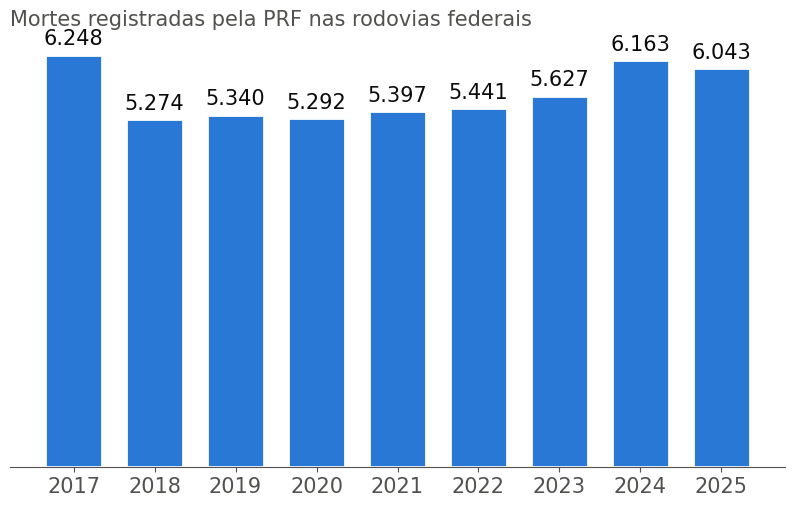

In [50]:
# 1. Mortes por ano
mortes = df.groupby("ano")["mortos"].sum()
fig, ax = plt.subplots()
barras = ax.bar(mortes.index.astype(str), mortes, color=AZUL, width=0.7, edgecolor=FUNDO, linewidth=2)
ax.bar_label(barras, labels=[milhar(v) for v in mortes], padding=4, color=TEXTO)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_ylabel("")
ax.set_title("Mortes registradas pela PRF nas rodovias federais", loc="left", color=TEXTO_2)
salvar(fig, "01_mortes_por_ano")

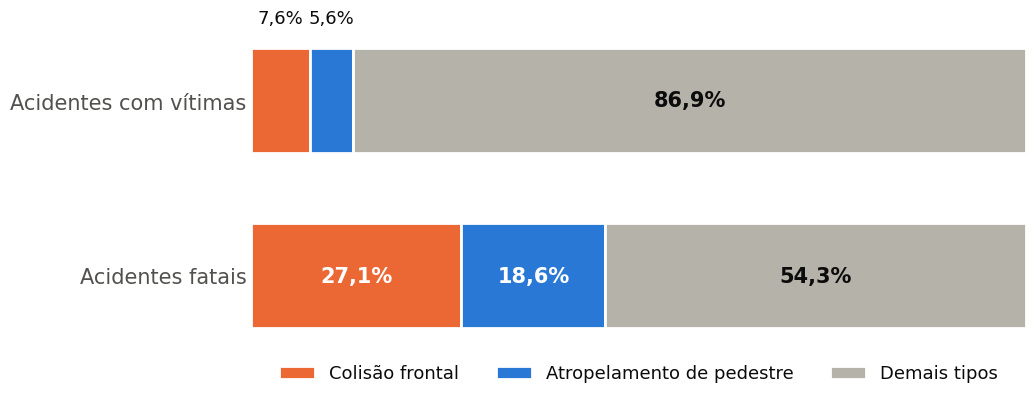

In [51]:
# 2. Parcela dos acidentes e dos fatais
grupos = df["tipo"].map({"Colisão frontal": "Colisão frontal", "Atropelamento de Pedestre": "Atropelamento de pedestre"}).fillna("Demais tipos")
ordem_grupos = ["Colisão frontal", "Atropelamento de pedestre", "Demais tipos"]
partes = pd.DataFrame({
    "Acidentes com vítimas": grupos.value_counts(normalize=True),
    "Acidentes fatais": grupos[df["fatal"] == 1].value_counts(normalize=True),
}).loc[ordem_grupos].T.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4))
esquerda = np.zeros(len(partes))
for grupo, cor in zip(ordem_grupos, [LARANJA, AZUL, CINZA]):
    ax.barh(partes.index, partes[grupo], left=esquerda, color=cor, edgecolor=FUNDO, linewidth=2, height=0.6, label=grupo)
    for i, v in enumerate(partes[grupo]):
        if v >= 0.10:
            ax.text(esquerda[i] + v / 2, i, pct(v), ha="center", va="center",
                    color="white" if cor != CINZA else TEXTO, fontsize=15, fontweight="bold")
        else:  # fatia estreita: rótulo acima da barra
            ax.text(esquerda[i] + v / 2, i + 0.42, pct(v), ha="center", va="bottom", color=TEXTO, fontsize=13)
    esquerda += partes[grupo].values
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=13)
salvar(fig, "02_parcela_frontal_pedestre")

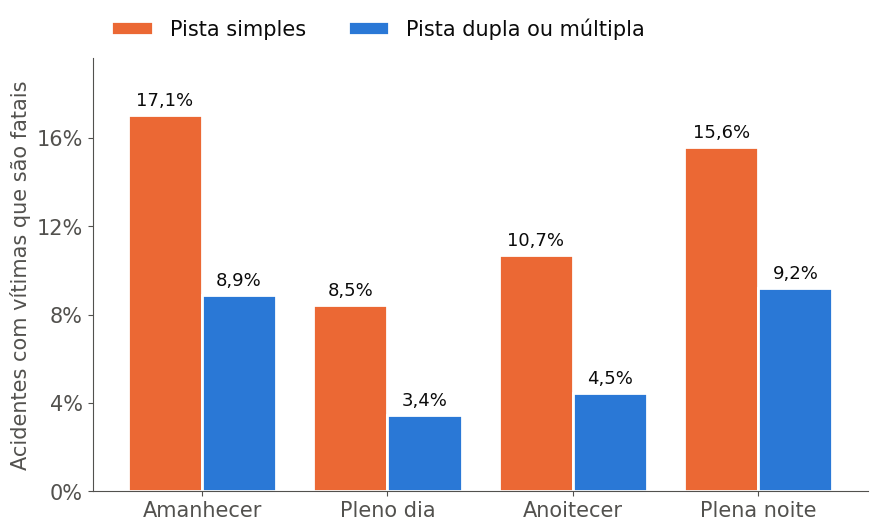

In [52]:
# 3. Fase do dia × tipo de pista
pista = np.where(df["tipo_pista"] == "Simples", "Pista simples", "Pista dupla ou múltipla")
fases = ["Amanhecer", "Pleno dia", "Anoitecer", "Plena Noite"]
grade = df.groupby([df["fase_dia"], pista])["fatal"].mean().unstack().loc[fases]
x = np.arange(len(fases))
fig, ax = plt.subplots()
for desloc, coluna, cor in [(-0.2, "Pista simples", LARANJA), (0.2, "Pista dupla ou múltipla", AZUL)]:
    barras = ax.bar(x + desloc, grade[coluna], width=0.4, color=cor, edgecolor=FUNDO, linewidth=2, label=coluna)
    ax.bar_label(barras, labels=[pct(v) for v in grade[coluna]], padding=4, fontsize=13)
ax.set_xticks(x, ["Amanhecer", "Pleno dia", "Anoitecer", "Plena noite"])
ax.yaxis.set_major_locator(MultipleLocator(0.04))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, grade.max().max() * 1.15)
ax.set_ylabel("Acidentes com vítimas que são fatais")
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1), ncol=2)
salvar(fig, "03_fase_do_dia_e_pista")

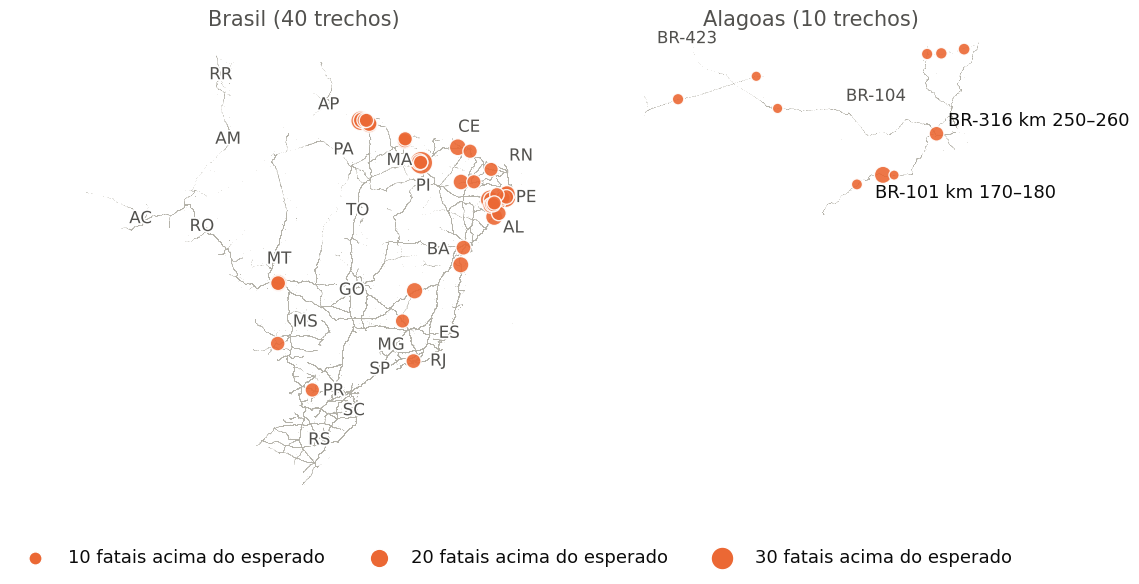

In [53]:
# 4. Trechos com maior excesso sobre o esperado (Brasil e Alagoas)
salvar(mapa_trechos(largura=12, fonte=15), "04_mapa_trechos")

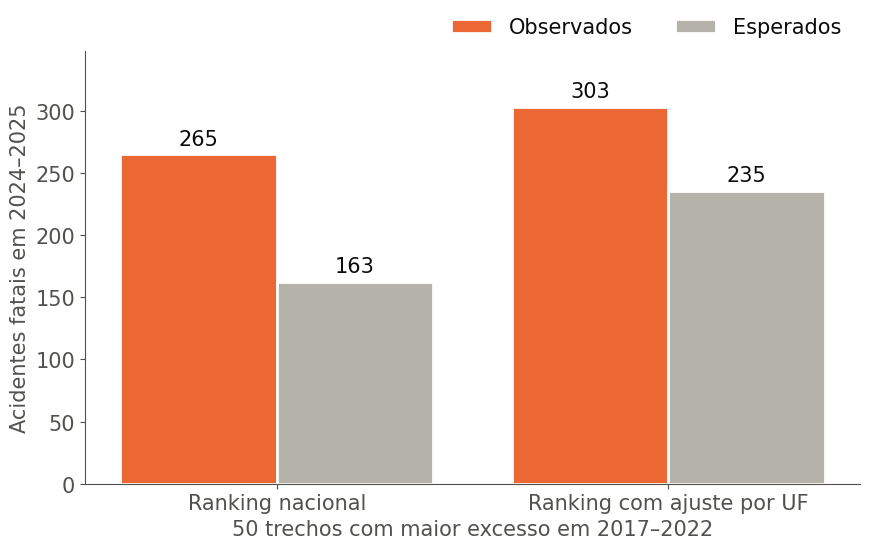

In [54]:
# 5. Fatais observados e esperados em 2024–2025 nos trechos escolhidos com dados de 2017–2022
comparacao_slide = pd.DataFrame({
    "Observados": [seguem["fatais"].sum(), seguem_uf["fatais"].sum()],
    "Esperados": [seguem["esperados"].sum(), seguem_uf["esperados"].sum()],
}, index=["Ranking nacional", "Ranking com ajuste por UF"])
x = np.arange(len(comparacao_slide))
fig, ax = plt.subplots()
for desloc, coluna, cor in [(-0.2, "Observados", LARANJA), (0.2, "Esperados", CINZA)]:
    barras = ax.bar(x + desloc, comparacao_slide[coluna], width=0.4, color=cor, edgecolor=FUNDO, linewidth=2, label=coluna)
    ax.bar_label(barras, labels=[milhar(v) for v in comparacao_slide[coluna]], padding=4)
ax.set_xticks(x, comparacao_slide.index)
ax.set_ylim(0, comparacao_slide.max().max() * 1.15)
ax.set_ylabel("Acidentes fatais em 2024–2025")
ax.set_xlabel("50 trechos com maior excesso em 2017–2022")
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 1.12), ncol=2)
salvar(fig, "05_observados_esperados")

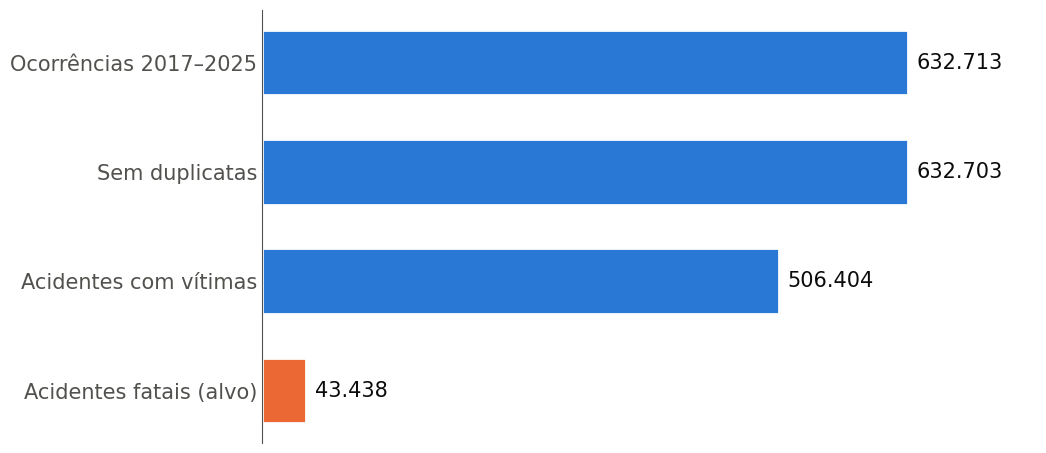

In [55]:
# 6. Funil da preparação
etapas = pd.Series({
    "Ocorrências 2017–2025": funil["Ocorrências 2017–2025"],
    "Sem duplicatas": funil["Sem duplicatas"],
    "Acidentes com vítimas": funil["Com vítimas"],
    "Acidentes fatais (alvo)": funil["Fatais"],
}).iloc[::-1]
fig, ax = plt.subplots()
barras = ax.barh(etapas.index, etapas, color=[LARANJA, AZUL, AZUL, AZUL], edgecolor=FUNDO, linewidth=2, height=0.6)
ax.bar_label(barras, labels=[milhar(v) for v in etapas], padding=6)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, etapas.max() * 1.2)
salvar(fig, "06_funil_preparacao")

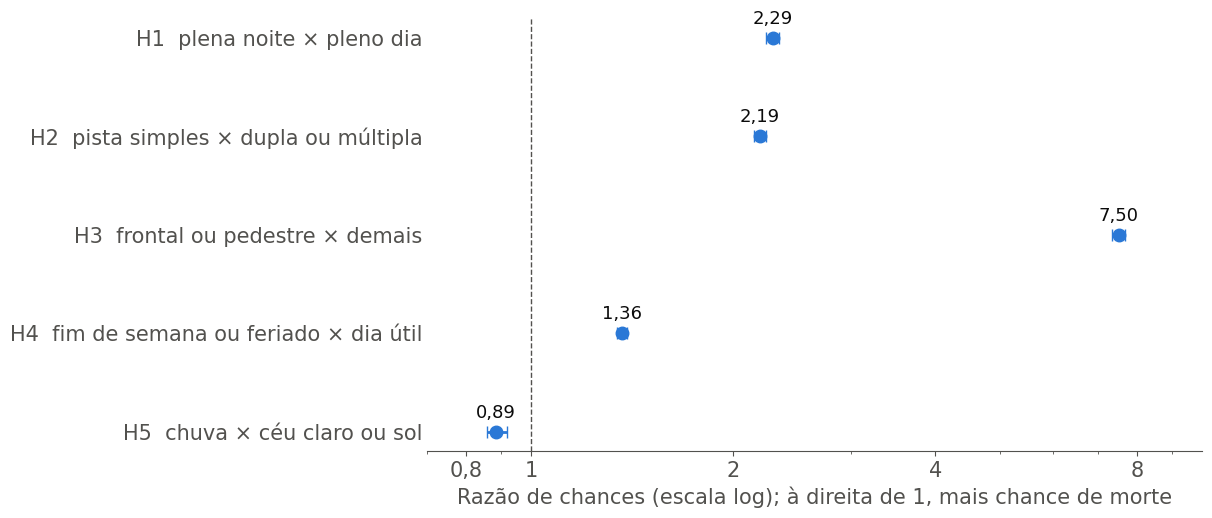

In [56]:
# 7. Hipóteses: razão de chances com intervalo de 95%
rotulos = {"H1": "H1  plena noite × pleno dia", "H2": "H2  pista simples × dupla ou múltipla",
           "H3": "H3  frontal ou pedestre × demais", "H4": "H4  fim de semana ou feriado × dia útil",
           "H5": "H5  chuva × céu claro ou sol"}
hip = pd.DataFrame(resultados).T.iloc[::-1]
ic = hip["IC 95%"].str.split("–", expand=True).astype(float)
rc = hip["razão de chances"].astype(float)
fig, ax = plt.subplots()
posicoes = np.arange(len(hip))
ax.errorbar(rc, posicoes, xerr=[rc - ic[0], ic[1] - rc], fmt="o", color=AZUL, markersize=9, capsize=4, linewidth=2)
for yi, v in zip(posicoes, rc):
    ax.annotate(f"{v:.2f}".replace(".", ","), (v, yi), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=13)
ax.axvline(1, color=TEXTO_2, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.8, 1, 2, 4, 8], ["0,8", "1", "2", "4", "8"])
ax.set_xlim(0.7, 10)
ax.set_yticks(posicoes, [rotulos[h] for h in hip.index])
ax.set_xlabel("Razão de chances (escala log); à direita de 1, mais chance de morte")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
salvar(fig, "07_hipoteses")

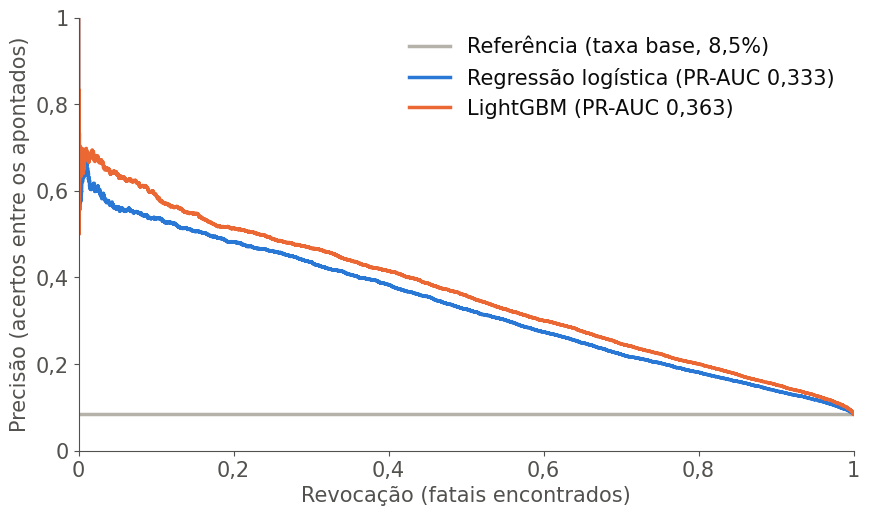

In [57]:
# 8. Curvas de precisão e revocação no teste
fig, ax = plt.subplots()
ax.axhline(y[teste].mean(), color=CINZA, linewidth=2.5, label=f"Referência (taxa base, {pct(y[teste].mean())})")
for nome, rotulo, cor in [("regressão logística", "Regressão logística", AZUL), ("LightGBM", "LightGBM", LARANJA)]:
    p = modelos[nome].predict_proba(X[teste])[:, 1]
    prec, rev, _ = precision_recall_curve(y[teste], p)
    ax.plot(rev, prec, color=cor, linewidth=2.5,
            label=f"{rotulo} (PR-AUC {average_precision_score(y[teste], p):.3f})".replace(".", ","))
ax.set(xlabel="Revocação (fatais encontrados)", ylabel="Precisão (acertos entre os apontados)", xlim=(0, 1), ylim=(0, 1))
ax.xaxis.set_major_formatter(virgula)
ax.yaxis.set_major_formatter(virgula)
ax.legend(frameon=False)
salvar(fig, "08_precisao_revocacao")

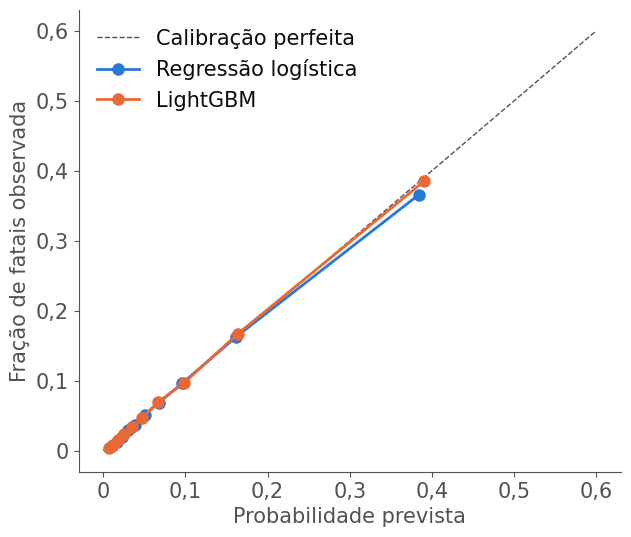

In [58]:
# 9. Calibração no teste
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 0.6], [0, 0.6], color=TEXTO_2, linestyle="--", linewidth=1, label="Calibração perfeita")
for nome, rotulo, cor in [("regressão logística", "Regressão logística", AZUL), ("LightGBM", "LightGBM", LARANJA)]:
    p = modelos[nome].predict_proba(X[teste])[:, 1]
    frac, medio = calibration_curve(y[teste], p, n_bins=10, strategy="quantile")
    ax.plot(medio, frac, "o-", color=cor, linewidth=2, markersize=8, label=rotulo)
ax.set(xlabel="Probabilidade prevista", ylabel="Fração de fatais observada")
ax.xaxis.set_major_formatter(virgula)
ax.yaxis.set_major_formatter(virgula)
ax.legend(frameon=False)
salvar(fig, "09_calibracao")

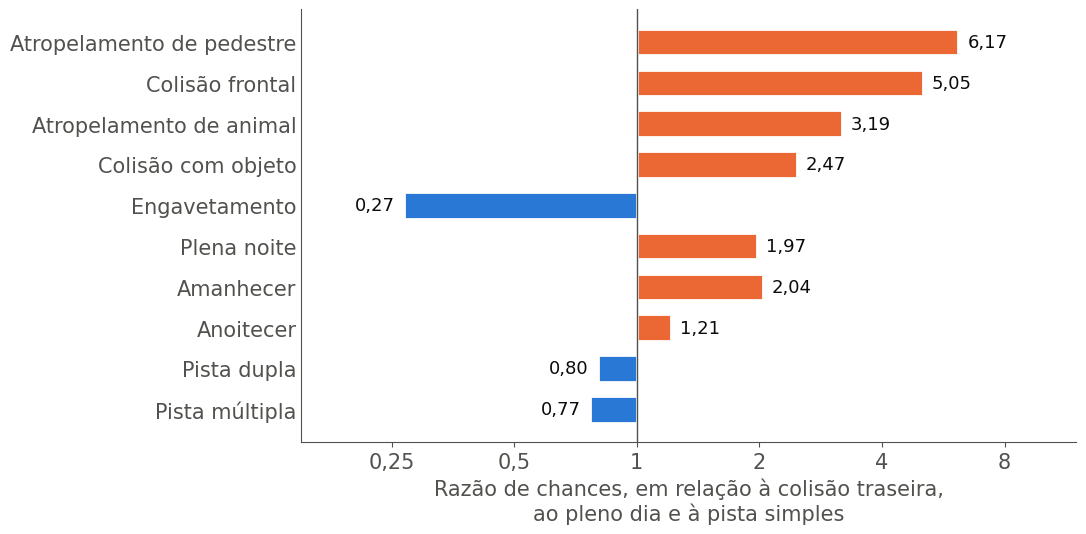

In [59]:
# 10. Razões de chances da regressão logística (seleção)
selecao = {
    "tipo_Atropelamento de Pedestre": "Atropelamento de pedestre", "tipo_Colisão frontal": "Colisão frontal",
    "tipo_Atropelamento de Animal": "Atropelamento de animal", "tipo_Colisão com objeto": "Colisão com objeto",
    "tipo_Engavetamento": "Engavetamento", "fase_dia_Plena Noite": "Plena noite", "fase_dia_Amanhecer": "Amanhecer",
    "fase_dia_Anoitecer": "Anoitecer", "tipo_pista_Dupla": "Pista dupla", "tipo_pista_Múltipla": "Pista múltipla",
}
rc_log = chances[list(selecao)].rename(selecao).iloc[::-1]
fig, ax = plt.subplots()
cores = [LARANJA if v > 1 else AZUL for v in rc_log]
barras = ax.barh(rc_log.index, np.log(rc_log), color=cores, edgecolor=FUNDO, linewidth=2, height=0.65)
for i, v in enumerate(rc_log):
    ax.text(np.log(v) + (0.05 if v > 1 else -0.05), i, f"{v:.2f}".replace(".", ","), va="center",
            ha="left" if v > 1 else "right", fontsize=13)
ax.axvline(0, color=TEXTO_2, linewidth=1)
marcas = [0.25, 0.5, 1, 2, 4, 8]
ax.set_xticks(np.log(marcas), ["0,25", "0,5", "1", "2", "4", "8"])
ax.set_xlim(np.log(0.15), np.log(12))
ax.set_xlabel("Razão de chances, em relação à colisão traseira,\nao pleno dia e à pista simples")
ax.tick_params(axis="y", length=0)
salvar(fig, "10_razoes_de_chances")

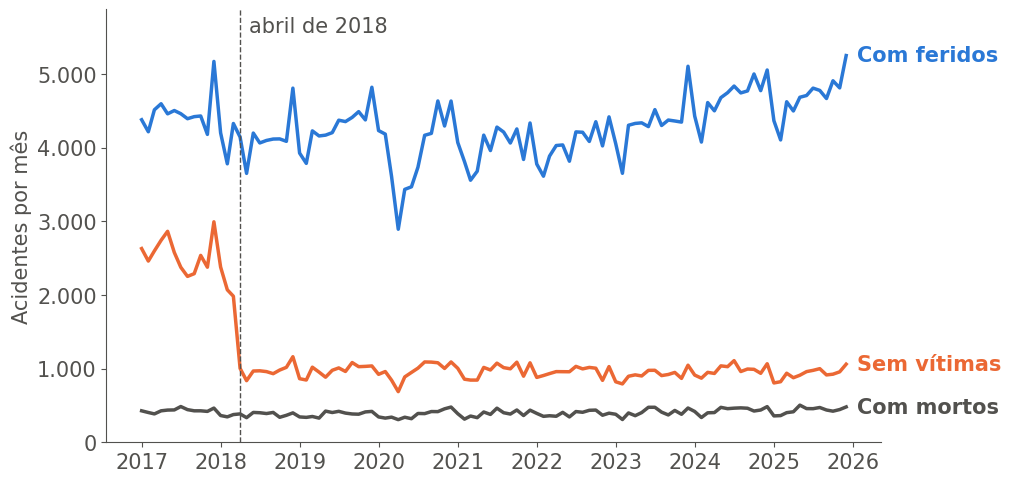

In [60]:
# 11. Acidentes por mês em cada classe: a quebra de registro de abril de 2018
serie = mensal.copy()
serie.index = serie.index.to_timestamp()
fig, ax = plt.subplots()
for classe, rotulo, cor in [("Com Vítimas Feridas", "Com feridos", AZUL), ("Sem Vítimas", "Sem vítimas", LARANJA),
                            ("Com Vítimas Fatais", "Com mortos", TEXTO_2)]:
    ax.plot(serie.index, serie[classe], color=cor, linewidth=2.5)
    ax.annotate(rotulo, (serie.index[-1], serie[classe].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=cor, fontweight="bold")
quebra = pd.Timestamp("2018-04-01")
ax.set_ylim(0, serie.max().max() * 1.12)
ax.axvline(quebra, color=TEXTO_2, linestyle="--", linewidth=1)
ax.text(quebra + pd.Timedelta(days=40), serie.max().max() * 1.06, "abril de 2018", color=TEXTO_2)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: milhar(v)))
ax.set_ylabel("Acidentes por mês")
salvar(fig, "11_quebra_de_registro")